In [1]:
!pip -q install ase matplotlib numpy pandas


In [2]:

from ase.build import bulk
from ase.calculators.emt import EMT
import numpy as np
import matplotlib.pyplot as plt

# Create a face-centered cubic copper crystal
copper = bulk("Cu", "fcc", a=3.6)

# Attach the EMT scientific calculator
copper.calc = EMT()

# Calculate basic properties
energy = copper.get_potential_energy()
volume = copper.get_volume()

print("=== ASE Copper Simulation ===")
print("Material: Copper (Cu)")
print("Crystal structure: FCC")
print("Number of atoms:", len(copper))
print("Volume:", round(volume, 4), "Å³")
print("Potential energy:", round(energy, 4), "eV")


=== ASE Copper Simulation ===
Material: Copper (Cu)
Crystal structure: FCC
Number of atoms: 1
Volume: 11.664 Å³
Potential energy: -0.0067 eV


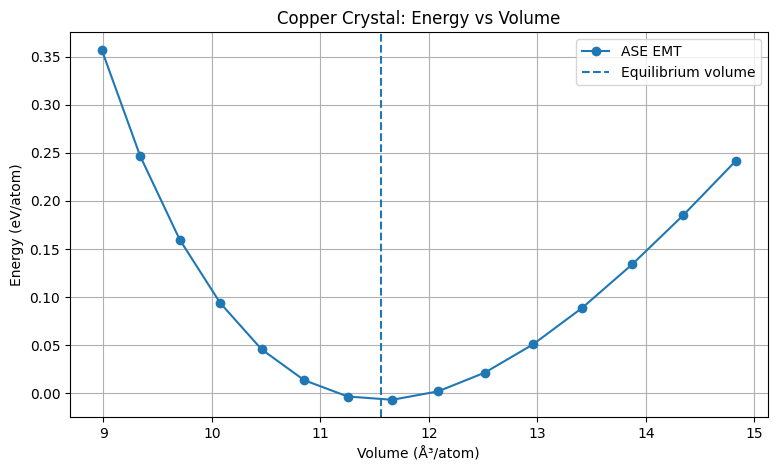

Equilibrium volume: 11.5633 Å³/atom
Minimum energy: -0.0066 eV/atom
Bulk modulus: 0.8276 eV/Å³


In [3]:

from ase.eos import EquationOfState

# Calculate energy at different lattice parameters
lattice_constants = np.linspace(3.3, 3.9, 15)
volumes = []
energies = []

for a in lattice_constants:
    atoms = bulk("Cu", "fcc", a=a)
    atoms.calc = EMT()

    volumes.append(atoms.get_volume())
    energies.append(atoms.get_potential_energy())

# Fit an equation of state
eos = EquationOfState(volumes, energies)
v0, e0, bulk_modulus = eos.fit()

# Plot the energy-volume curve
plt.figure(figsize=(9, 5))
plt.plot(volumes, energies, "o-", label="ASE EMT")
plt.axvline(v0, linestyle="--", label="Equilibrium volume")
plt.xlabel("Volume (Å³/atom)")
plt.ylabel("Energy (eV/atom)")
plt.title("Copper Crystal: Energy vs Volume")
plt.legend()
plt.grid(True)
plt.show()

print("Equilibrium volume:", round(v0, 4), "Å³/atom")
print("Minimum energy:", round(e0, 4), "eV/atom")
print("Bulk modulus:", round(bulk_modulus, 4), "eV/Å³")


All scientific validation checks passed!
Equilibrium lattice constant: 3.5896 Å
Bulk modulus: 132.60 GPa


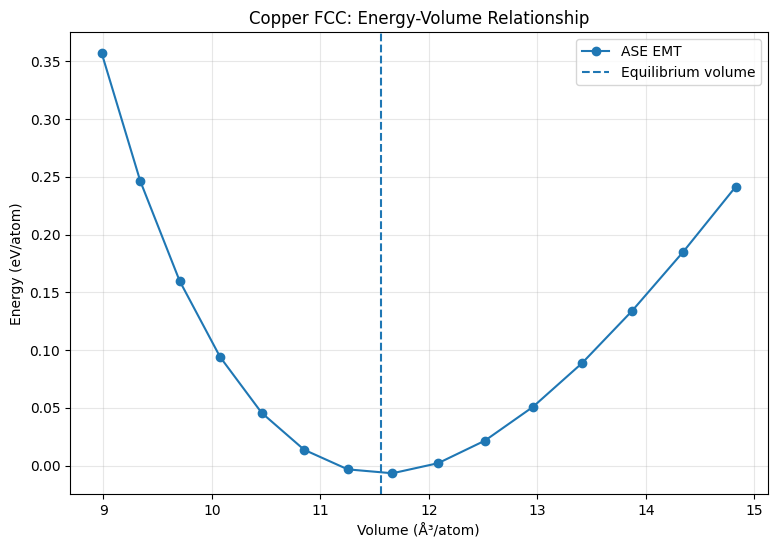

CSV, PNG and JSON files saved successfully!


In [4]:

import pandas as pd
import json
from ase.units import kJ

# Convert scientific units
bulk_modulus_gpa = bulk_modulus / kJ * 1e24

# Calculate equilibrium FCC lattice constant
a0 = (4 * v0) ** (1 / 3)

# Scientific validation checks
assert len(volumes) == 15
assert len(energies) == 15
assert min(volumes) < v0 < max(volumes)
assert bulk_modulus > 0
assert abs(copper.get_volume() - 3.6**3 / 4) < 1e-6

print("All scientific validation checks passed!")

print(f"Equilibrium lattice constant: {a0:.4f} Å")
print(f"Bulk modulus: {bulk_modulus_gpa:.2f} GPa")

# Save numerical simulation results
df = pd.DataFrame({
    "lattice_constant_A": lattice_constants,
    "volume_A3": volumes,
    "energy_eV": energies
})
df.to_csv("copper_simulation_results.csv", index=False)

# Save a high-resolution scientific figure
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(volumes, energies, "o-", label="ASE EMT")
ax.axvline(v0, linestyle="--", label="Equilibrium volume")
ax.set_xlabel("Volume (Å³/atom)")
ax.set_ylabel("Energy (eV/atom)")
ax.set_title("Copper FCC: Energy-Volume Relationship")
ax.legend()
ax.grid(True, alpha=0.3)

fig.savefig("copper_energy_volume.png", dpi=300,
            bbox_inches="tight")
plt.show()
plt.close(fig)

# Save model-derived reference values
summary = {
    "material": "Copper",
    "structure": "FCC",
    "simulation_method": "ASE EMT",
    "equilibrium_volume_A3": float(v0),
    "equilibrium_lattice_constant_A": float(a0),
    "minimum_energy_eV": float(e0),
    "bulk_modulus_GPa": float(bulk_modulus_gpa)
}

with open("simulation_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("CSV, PNG and JSON files saved successfully!")
